# What Predicts a School's Average SAT Score in New York City?

**Dataset:** New York City Department of Education public data for 2011-12. SAT results, student demographics, class sizes, AP participation and the high school directory, joined on the school identifier (DBN). 412 high schools with a reported SAT average.

---

## What this analysis can and cannot be

Every number here is a **school-level aggregate**. A row is a school, not a student: the SAT figure is that school's average, and the demographic figures are that school's composition.

This matters more than any result below. A correlation between a school's composition and its mean score describes **schools**, and says nothing about any individual student. Treating an aggregate relationship as if it held for individuals is the ecological fallacy, and it is the single easiest way to turn this dataset into a wrong and harmful claim.

There is also no randomisation anywhere in this data. NYC high schools admit students through screening, auditions, lotteries and, for eight of them, a citywide entrance exam. Schools differ systematically in who applies and who is admitted before any schooling happens. Nothing in this notebook can separate what a school *does* from who a school *enrols*, so none of it is causal.

With that stated, there is still a worthwhile question: **the raw correlations are routinely reported from this dataset, so how many of them survive the most obvious control?**

## 1. Building the combined dataset

In [1]:
%matplotlib inline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.width", 170)
DATA = "schools/"

sat = pd.read_csv(DATA + "sat_results.csv")
demographics = pd.read_csv(DATA + "demographics.csv")
class_size = pd.read_csv(DATA + "class_size.csv")
ap = pd.read_csv(DATA + "ap_2010.csv")

SAT_PARTS = ["SAT Critical Reading Avg. Score", "SAT Math Avg. Score",
             "SAT Writing Avg. Score"]
for c in SAT_PARTS + ["Num of SAT Test Takers"]:
    sat[c] = pd.to_numeric(sat[c], errors="coerce")

# min_count=3 so a school missing any section gets NaN rather than a
# partial total that would look like a very low score.
sat["sat_score"] = sat[SAT_PARTS].sum(axis=1, min_count=3)

print("SAT file: %d schools, %d with a complete score" %
      (len(sat), sat["sat_score"].notna().sum()))
print("the other %d are suppressed, which NYC does for schools with fewer than" %
      sat["sat_score"].isna().sum())
print("five test takers, so the smallest schools are missing by design.")

SAT file: 478 schools, 421 with a complete score
the other 57 are suppressed, which NYC does for schools with fewer than
five test takers, so the smallest schools are missing by design.


In [2]:
# Demographics covers several years; keep the one matching the SAT data.
demographics = demographics[demographics["schoolyear"] == 20112012].copy()

# class_size has no DBN column: it has to be built from district and school code.
class_size["DBN"] = (class_size["CSD"].astype(str).str.zfill(2) +
                     class_size["SCHOOL CODE"])
high_school_classes = class_size[(class_size["GRADE "] == "09-12") &
                                 (class_size["PROGRAM TYPE"] == "GEN ED")]
class_sizes = (high_school_classes.groupby("DBN")
               .agg(avg_class_size=("AVERAGE CLASS SIZE", "mean")).reset_index())

ap["AP Test Takers "] = pd.to_numeric(ap["AP Test Takers "], errors="coerce")
ap = ap.groupby("DBN").first().reset_index()

DEMO_COLS = ["frl_percent", "ell_percent", "sped_percent", "asian_per",
             "black_per", "hispanic_per", "white_per", "total_enrollment"]
for c in DEMO_COLS:
    demographics[c] = pd.to_numeric(demographics[c], errors="coerce")

schools = (sat.merge(demographics[["DBN"] + DEMO_COLS], on="DBN")
           .merge(class_sizes, on="DBN", how="left")
           .merge(ap[["DBN", "AP Test Takers "]], on="DBN", how="left"))
schools = schools[schools["sat_score"].notna()].copy()
schools["ap_per_student"] = schools["AP Test Takers "] / schools["total_enrollment"]

print("combined: %d schools" % len(schools))
print("sat_score: mean %.0f, sd %.0f, range %.0f to %.0f" % (
      schools["sat_score"].mean(), schools["sat_score"].std(),
      schools["sat_score"].min(), schools["sat_score"].max()))
print()
print("Note what frl_percent is: the share of students eligible for free or")
print("reduced-price lunch, which is the standard school-level poverty proxy.")
print("citywide mean: %.1f%%" % schools["frl_percent"].mean())

combined: 412 schools
sat_score: mean 1209, sd 176, range 887 to 2096

Note what frl_percent is: the share of students eligible for free or
reduced-price lunch, which is the standard school-level poverty proxy.
citywide mean: 66.1%


## 2. The raw correlations

In [3]:
CORRELATES = DEMO_COLS + ["avg_class_size", "ap_per_student", "Num of SAT Test Takers"]
raw_corr = (schools[CORRELATES + ["sat_score"]].corr()["sat_score"]
            .drop("sat_score").sort_values())
print("correlation with a school's mean SAT score:")
print(raw_corr.round(3).to_string())

correlation with a school's mean SAT score:
frl_percent              -0.721
sped_percent             -0.423
ell_percent              -0.376
hispanic_per             -0.363
black_per                -0.310
total_enrollment          0.378
avg_class_size            0.396
Num of SAT Test Takers    0.482
asian_per                 0.545
white_per                 0.652
ap_per_student            0.698


Two things stand out before any further work.

**Poverty is the strongest single correlate in the dataset.** `frl_percent` at **-0.721** beats every racial composition variable, including `white_per` at +0.652. Since school poverty and school racial composition are themselves heavily correlated in a segregated school system, the racial correlations and the poverty correlation are substantially the same fact reported twice.

**Average class size correlates positively with SAT scores (+0.396).** Read naively, that says crowding students into bigger classes raises their scores, which no one believes. It is a clue that something structural is driving both: large schools are disproportionately the long-established, selective ones.

So the obvious next step is to ask what survives once poverty is held constant.

## 3. Holding poverty constant

A partial correlation: regress both the SAT score and the variable of interest on `frl_percent`, then correlate what is left over. Whatever remains is the association that school poverty does not already account for.

Ordinary least squares via `numpy.linalg.lstsq`, so the notebook has no dependency beyond pandas and NumPy.

In [4]:
model_data = schools.dropna(subset=DEMO_COLS + ["avg_class_size"]).copy()
print("complete cases: %d of %d schools" % (len(model_data), len(schools)))

def design_matrix(columns):
    n = len(columns[0])
    return np.column_stack([np.ones(n)] + [np.asarray(c, dtype=float) for c in columns])

def ols(y, columns):
    """Returns coefficients and R squared."""
    X = design_matrix(columns)
    y = np.asarray(y, dtype=float)
    beta, _, _, _ = np.linalg.lstsq(X, y, rcond=None)
    fitted = X @ beta
    return beta, 1 - ((y - fitted) ** 2).sum() / ((y - y.mean()) ** 2).sum()

def residuals_after(y, control):
    beta, _ = ols(y, [control])
    return np.asarray(y, dtype=float) - (beta[0] + beta[1] * np.asarray(control, dtype=float))

sat_resid = residuals_after(model_data["sat_score"], model_data["frl_percent"])

print()
print("%-18s %9s %12s %10s" % ("variable", "raw r", "partial r", "change"))
rows = []
for v in ["white_per", "asian_per", "black_per", "hispanic_per",
          "ell_percent", "sped_percent", "avg_class_size", "total_enrollment"]:
    raw = np.corrcoef(model_data["sat_score"], model_data[v])[0, 1]
    partial = np.corrcoef(sat_resid, residuals_after(model_data[v], model_data["frl_percent"]))[0, 1]
    shrink = 100 * (1 - abs(partial) / abs(raw))
    rows.append({"variable": v, "raw_r": raw, "partial_r": partial, "shrink_pct": shrink})
    print("%-18s %9.3f %12.3f %9.0f%%" % (v, raw, partial, shrink))

partials = pd.DataFrame(rows)
print()
print("variance in school mean SAT explained:")
print("  poverty alone:              R2 = %.3f" % ols(model_data["sat_score"], [model_data["frl_percent"]])[1])
print("  four racial shares alone:   R2 = %.3f" % ols(model_data["sat_score"],
      [model_data[c] for c in ["white_per", "asian_per", "black_per", "hispanic_per"]])[1])
print("  poverty and all four:       R2 = %.3f" % ols(model_data["sat_score"],
      [model_data[c] for c in ["frl_percent", "white_per", "asian_per", "black_per", "hispanic_per"]])[1])
print()
print("0.516 + 0.562 = 1.078, but together they reach only 0.652, so the two")
print("sets of variables are largely describing the same variation.")

complete cases: 401 of 412 schools

variable               raw r    partial r     change
white_per              0.647        0.288        56%
asian_per              0.552        0.455        18%
black_per             -0.303       -0.386       -27%
hispanic_per          -0.364        0.052        86%
ell_percent           -0.380       -0.129        66%
sped_percent          -0.421       -0.343        19%
avg_class_size         0.396        0.193        51%
total_enrollment       0.386        0.201        48%

variance in school mean SAT explained:
  poverty alone:              R2 = 0.516
  four racial shares alone:   R2 = 0.562
  poverty and all four:       R2 = 0.652

0.516 + 0.562 = 1.078, but together they reach only 0.652, so the two
sets of variables are largely describing the same variation.


**The result is mixed, and reporting it honestly means not rounding it toward a tidy story.**

Poverty absorbs most of some associations and almost none of others:

- **`hispanic_per` collapses from -0.364 to +0.052.** The raw association was essentially school poverty wearing a different label.
- **`ell_percent` falls from -0.380 to -0.129,** a 66% reduction. What remains is unsurprising on its face: the SAT is administered in English.
- **`white_per` halves,** from 0.647 to 0.288.
- **`avg_class_size` halves,** from 0.396 to 0.193, and stays positive.
- **`asian_per` barely moves,** 0.552 to 0.455.
- **`black_per` gets stronger,** from -0.303 to -0.386.

That last line is the one a tidy narrative would want to omit. If the whole story were "it is really just poverty", controlling for poverty would shrink every association. It does not. School-level free-lunch eligibility is a crude binary-threshold measure of family income and plainly does not capture everything that differs across these schools, so the residual associations are a measure of what this one control misses, not evidence about students.

The R-squared figures make the overlap concrete: poverty alone explains 51.6% of the variance in school mean scores, the four racial shares alone explain 56.2%, and together they reach only 65.2%. Two sets of variables that between them would account for 108% of the variance if independent are in fact describing largely the same segregation.

## 4. The eight exam schools

New York admits students to eight specialized high schools through a single citywide test, the SHSAT. If any subset of schools were going to manufacture these correlations on its own, it would be these.

Matched by exact DBN rather than by name, because a substring search for "STUYVESANT" also catches Bedford Stuyvesant Preparatory, an unrelated and very differently situated school.

In [5]:
SPECIALIZED = {
    "02M475": "Stuyvesant", "10X445": "Bronx Science", "13K430": "Brooklyn Tech",
    "31R605": "Staten Island Tech", "10X696": "HS of American Studies",
    "28Q687": "Queens HS for the Sciences", "05M692": "HSMSE at City College",
    "14K449": "Brooklyn Latin",
}
schools["specialized"] = schools["DBN"].isin(SPECIALIZED)

exam = schools[schools["specialized"]]
rest = schools[~schools["specialized"]]

print("matched %d of 8 specialized schools" % len(exam))
print(exam[["DBN", "SCHOOL NAME", "sat_score", "frl_percent"]]
      .sort_values("sat_score", ascending=False).to_string(index=False))
print()
gap = exam["sat_score"].mean() - rest["sat_score"].mean()
print("mean SAT: specialized %.0f, all others %.0f" %
      (exam["sat_score"].mean(), rest["sat_score"].mean()))
print("gap: %.0f points, or %.2f standard deviations" % (gap, gap / schools["sat_score"].std()))
print("they are %.1f%% of schools and hold %d of the top 10 scores" %
      (100 * len(exam) / len(schools), schools.nlargest(10, "sat_score")["specialized"].sum()))
print("mean poverty rate: %.1f%% against %.1f%% elsewhere" %
      (exam["frl_percent"].mean(), rest["frl_percent"].mean()))
print()
print("DO THEY DRIVE THE CORRELATIONS?")
print("%-15s %13s %13s %9s" % ("variable", "all schools", "excluding 8", "change"))
for v in ["white_per", "asian_per", "black_per", "hispanic_per", "frl_percent"]:
    a = np.corrcoef(schools["sat_score"], schools[v])[0, 1]
    b = np.corrcoef(rest["sat_score"], rest[v])[0, 1]
    print("%-15s %13.3f %13.3f %+9.3f" % (v, a, b, b - a))

matched 8 of 8 specialized schools
   DBN                                                          SCHOOL NAME  sat_score  frl_percent
02M475                                               STUYVESANT HIGH SCHOOL     2096.0         30.3
10X445                                         BRONX HIGH SCHOOL OF SCIENCE     1969.0         34.2
31R605                                  STATEN ISLAND TECHNICAL HIGH SCHOOL     1953.0         17.0
10X696                    HIGH SCHOOL OF AMERICAN STUDIES AT LEHMAN COLLEGE     1920.0         20.8
28Q687                  QUEENS HIGH SCHOOL FOR THE SCIENCES AT YORK COLLEGE     1868.0         25.6
05M692 HIGH SCHOOL FOR MATHEMATICS, SCIENCE AND ENGINEERING AT CITY COLLEGE     1847.0         18.5
13K430                                       BROOKLYN TECHNICAL HIGH SCHOOL     1833.0         50.7
14K449                                           BROOKLYN LATIN SCHOOL, THE     1740.0         53.3

mean SAT: specialized 1903, all others 1196
gap: 708 points, or 

**No. Removing them barely moves anything.**

The eight schools are a striking illustration of selection: 1.9% of the city's high schools, averaging **4.03 standard deviations** above the rest, holding 7 of the top 10 scores, with a poverty rate of 31.3% against 66.8% elsewhere.

But drop all eight and the correlations stay put. The largest change is `asian_per`, from 0.545 to 0.442; `white_per` actually rises slightly. **The pattern is citywide, not an artifact of eight unusual schools**, which is a more uncomfortable finding than the alternative and the reason it is worth running the check rather than assuming.

## 5. Charts

The project asks specifically about class size, so it gets the second chart.

Chart 1: 3 figure texts, 0 out of bounds


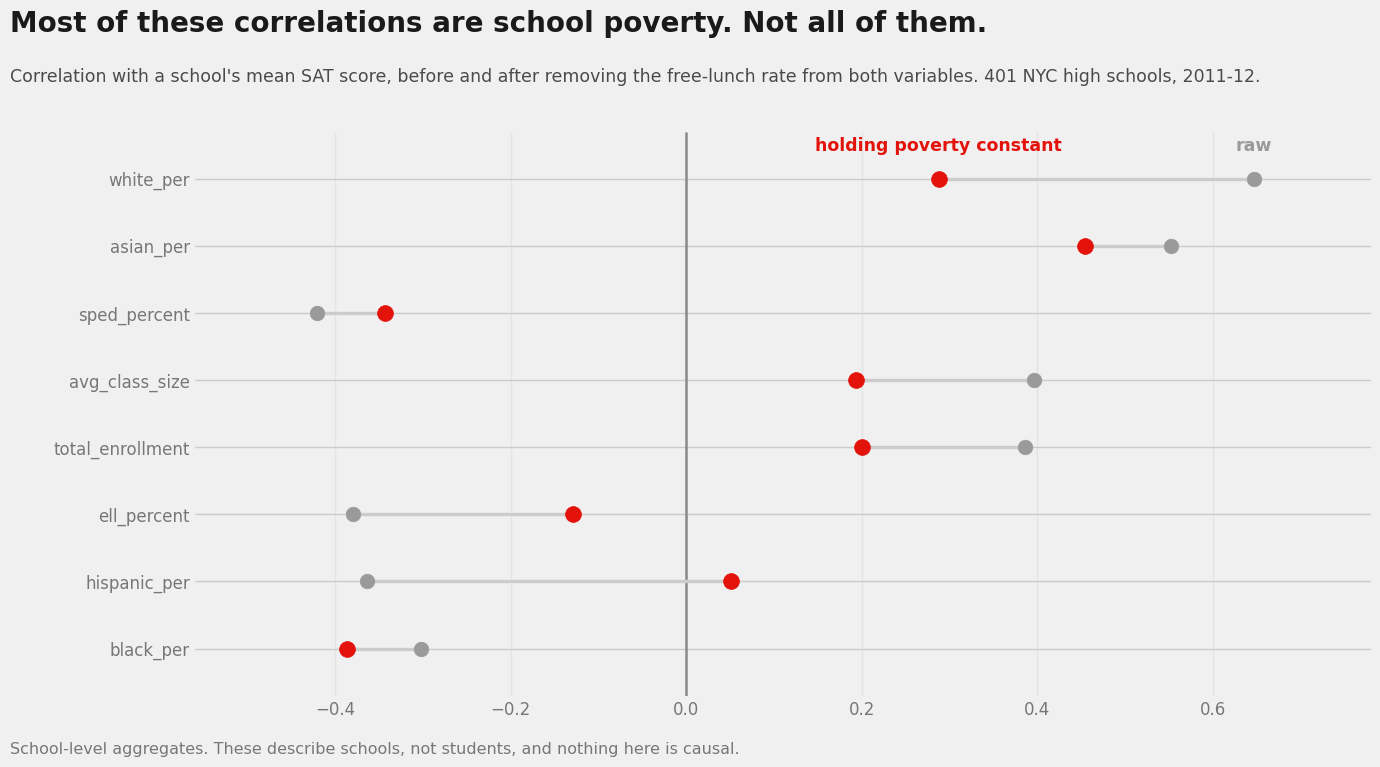

In [6]:
plt.style.use("fivethirtyeight")
C_RAW = "#9a9a9a"
C_PART = "#e3120b"
C_BLUE = "#2e86ab"

def audit(fig, label):
    """Confirm hand-placed text sits inside the canvas instead of trusting the eye."""
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    bad = []
    for t in fig.texts:
        bb = t.get_window_extent(renderer=r).transformed(fig.transFigure.inverted())
        if bb.y1 > 1.0 or bb.y0 < 0.0 or bb.x1 > 1.0 or bb.x0 < 0.0:
            bad.append((t.get_text()[:40], round(bb.y0, 3), round(bb.y1, 3)))
    print("%s: %d figure texts, %d out of bounds" % (label, len(fig.texts), len(bad)))
    for b in bad:
        print("   OUT OF BOUNDS:", b)
    return len(bad) == 0

# Chart 1: what survives controlling for poverty
order = partials.reindex(partials["raw_r"].abs().sort_values().index)
y = np.arange(len(order))

fig, ax = plt.subplots(figsize=(14, 8))
ax.axvline(0, color="#8a8a8a", linewidth=1.8, zorder=2)
for yi, (_, row) in zip(y, order.iterrows()):
    ax.plot([row["raw_r"], row["partial_r"]], [yi, yi], color="#cccccc",
            linewidth=2.4, zorder=3)
    ax.scatter([row["raw_r"]], [yi], s=110, color=C_RAW, zorder=4)
    ax.scatter([row["partial_r"]], [yi], s=130, color=C_PART, zorder=5)

ax.set_yticks(y)
ax.set_yticklabels(order["variable"], fontsize=12.5)
ax.set_ylim(-0.7, len(order) - 0.3)
ax.set_xlim(-0.56, 0.78)
ax.set_xticks([-0.4, -0.2, 0, 0.2, 0.4, 0.6])
ax.tick_params(labelsize=12, colors="#777777")
ax.grid(alpha=0.3, axis="x")
for s in ax.spines.values():
    s.set_visible(False)

top = len(order) - 1
ax.text(order.iloc[-1]["raw_r"], top + 0.42, "raw", color=C_RAW,
        fontsize=12.5, weight="bold", ha="center")
ax.text(order.iloc[-1]["partial_r"], top + 0.42, "holding poverty constant",
        color=C_PART, fontsize=12.5, weight="bold", ha="center")

fig.subplots_adjust(left=0.145, right=0.985, top=0.800, bottom=0.095)
fig.text(0.013, 0.925, "Most of these correlations are school poverty. Not all of them.",
         fontsize=20, weight="bold", color="#1a1a1a")
fig.text(0.013, 0.862,
         "Correlation with a school's mean SAT score, before and after removing the free-lunch rate from both variables. 401 NYC high schools, 2011-12.",
         fontsize=12.5, color="#4a4a4a")
fig.text(0.013, 0.022,
         "School-level aggregates. These describe schools, not students, and nothing here is causal.",
         fontsize=11.5, color="#777777")
ok1 = audit(fig, "Chart 1")
plt.show()

Chart 2: 3 figure texts, 0 out of bounds

all charts within bounds: True


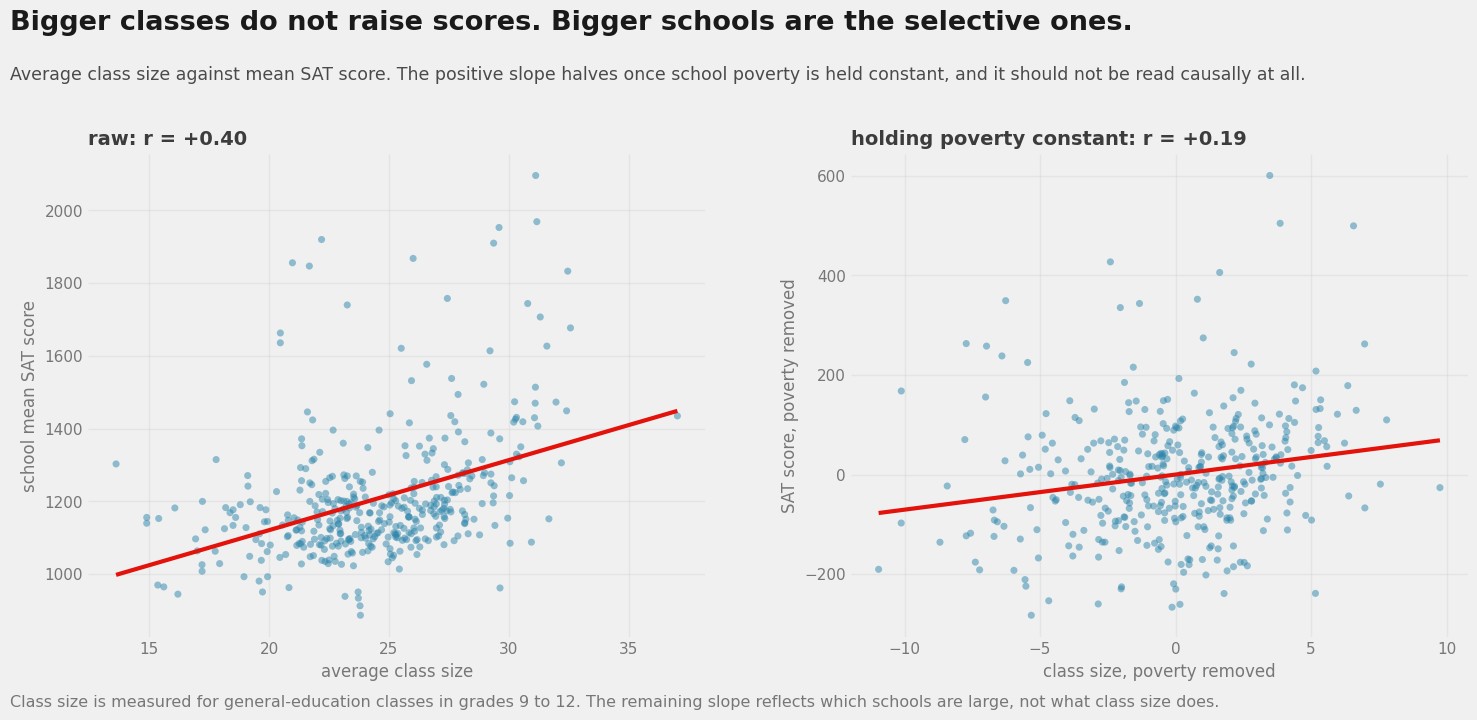

In [7]:
# Chart 2: the class size trap
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 7.5))

m = model_data
ax1.scatter(m["avg_class_size"], m["sat_score"], s=26, alpha=0.5,
            color=C_BLUE, edgecolors="none", zorder=3)
b, _ = ols(m["sat_score"], [m["avg_class_size"]])
xs = np.linspace(m["avg_class_size"].min(), m["avg_class_size"].max(), 50)
ax1.plot(xs, b[0] + b[1] * xs, color=C_PART, linewidth=3, zorder=4)
ax1.set_title("raw: r = +0.40", fontsize=14, weight="bold", color="#3c3c3c", loc="left")
ax1.set_xlabel("average class size", fontsize=12, color="#777777")
ax1.set_ylabel("school mean SAT score", fontsize=12, color="#777777")

cs_resid = residuals_after(m["avg_class_size"], m["frl_percent"])
ax2.scatter(cs_resid, sat_resid, s=26, alpha=0.5, color=C_BLUE,
            edgecolors="none", zorder=3)
b2, _ = ols(sat_resid, [cs_resid])
xs2 = np.linspace(cs_resid.min(), cs_resid.max(), 50)
ax2.plot(xs2, b2[0] + b2[1] * xs2, color=C_PART, linewidth=3, zorder=4)
ax2.set_title("holding poverty constant: r = +0.19", fontsize=14, weight="bold",
              color="#3c3c3c", loc="left")
ax2.set_xlabel("class size, poverty removed", fontsize=12, color="#777777")
ax2.set_ylabel("SAT score, poverty removed", fontsize=12, color="#777777")

for ax in (ax1, ax2):
    ax.tick_params(labelsize=11, colors="#777777")
    ax.grid(alpha=0.3)
    for s in ax.spines.values():
        s.set_visible(False)

fig.subplots_adjust(left=0.065, right=0.985, top=0.760, bottom=0.115, wspace=0.235)
fig.text(0.013, 0.925, "Bigger classes do not raise scores. Bigger schools are the selective ones.",
         fontsize=19.5, weight="bold", color="#1a1a1a")
fig.text(0.013, 0.858,
         "Average class size against mean SAT score. The positive slope halves once school poverty is held constant, and it should not be read causally at all.",
         fontsize=12.5, color="#4a4a4a")
fig.text(0.013, 0.022,
         "Class size is measured for general-education classes in grades 9 to 12. The remaining slope reflects which schools are large, not what class size does.",
         fontsize=11.5, color="#777777")
ok2 = audit(fig, "Chart 2")
print()
print("all charts within bounds:", bool(ok1 and ok2))
plt.show()

## 6. Conclusions

### The headline

**School poverty is the strongest single correlate of a school's mean SAT score (-0.721), ahead of every demographic composition variable.** Most of the demographic correlations usually reported from this dataset are substantially the same fact restated, but not all of them, and the exceptions are worth more than the rule.

### What survives holding poverty constant

| Variable | Raw | Partial | Change |
|---|---|---|---|
| hispanic_per | -0.364 | **+0.052** | collapses to nothing |
| ell_percent | -0.380 | -0.129 | down 66% |
| white_per | +0.647 | +0.288 | down 56% |
| avg_class_size | +0.396 | +0.193 | down 51% |
| total_enrollment | +0.386 | +0.201 | down 48% |
| sped_percent | -0.421 | -0.343 | down 19% |
| asian_per | +0.552 | +0.455 | down 18% |
| black_per | -0.303 | **-0.386** | **gets stronger** |

The `hispanic_per` association disappears entirely: it was school poverty under another name. The English-language-learner association falls by two thirds, and what remains is unsurprising given that the SAT is administered in English.

The `black_per` association **strengthens** under the control. A tidy "it is really just poverty" narrative would have to omit that line, so it does not get omitted here. Free-lunch eligibility is a crude threshold measure of family income, and the residual association measures what that one control fails to capture across these schools. It is not evidence about students.

**The overlap is the real finding.** Poverty alone explains 51.6% of the variance in school mean scores. The four racial shares alone explain 56.2%. Together they reach only 65.2%. Two sets of variables that would account for 108% between them if independent are describing largely the same segregation.

### Class size, which the brief asks about

Average class size correlates **positively** with SAT scores (+0.396). Nobody believes crowding raises scores. Holding poverty constant halves it to +0.193, and the remainder still should not be read causally: large schools in New York are disproportionately the long-established selective ones, so this measures which schools are big, not what class size does.

**The honest answer to "does class size affect SAT scores" from this data is that the question cannot be answered with it.**

### The eight exam schools do not explain the pattern

The specialized high schools are a dramatic illustration of selection: 1.9% of the city's high schools, **4.03 standard deviations** above the rest on average (1,903 against 1,196), holding 7 of the top 10 scores, with a 31.3% poverty rate against 66.8% elsewhere.

Remove all eight and the correlations barely move. The largest change is `asian_per`, 0.545 to 0.442; `white_per` rises slightly. The pattern is citywide, which is a more uncomfortable finding than "a handful of unusual schools skew the data" and the reason the check was worth running rather than assuming.

### What this analysis cannot support

- **These are school aggregates, so they describe schools and not students.** Reading a school-level correlation as a statement about individuals is the ecological fallacy. Nothing here supports any claim about any student or group of students.
- **Nothing here is causal.** NYC high schools admit by screening, audition, lottery and entrance exam. Schools differ in who applies and who is admitted before any teaching happens, and no variable in this data separates what a school does from who it enrols.
- **The SAT is itself a selected sample within each school.** The figure is the average among students who chose to sit it, so a school where few take the SAT is reporting a different kind of number from one where most do.
- **57 of 478 schools report no SAT score.** NYC suppresses results for fewer than five test takers, so the smallest schools are missing by design, not at random.
- **`frl_percent` is a threshold measure, not income.** It records eligibility for a benefit and cannot distinguish a school at the edge of the threshold from one far below it.
- **This is one school year, 2011-12,** and the SAT has since been redesigned, so none of these levels transfer to current scores.

### What would actually answer the question

Student-level data with prior achievement, allowing a value-added comparison: how much do students at a school gain relative to similar students who started in the same place? That is the measure that distinguishes a good school from a selective one, and it is not in this dataset.

---

*Data: New York City Department of Education, 2011-12 school year.*